In [1]:
import seaborn as sns

In [7]:
import pandas as pd

In [3]:
df = sns.load_dataset("taxis")
print(df.shape)
df.head()

(6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [4]:
# check for missing values

In [5]:
missing = df.isnull().sum()
print(missing[missing > 0])

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
# impute missing values

In [8]:
num_cols = df.select_dtypes(include="number").columns

In [11]:
for col in num_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"{col}: filled missing values with median = {median_val}")
    else:
        print(f"{col}: no missing values, nothing to impute")

passengers: no missing values, nothing to impute
distance: no missing values, nothing to impute
fare: no missing values, nothing to impute
tip: no missing values, nothing to impute
tolls: no missing values, nothing to impute
total: no missing values, nothing to impute


In [12]:
for col in ["payment", "pickup_borough", "dropoff_borough"]:
    if df[col].isnull().any():
        count = df[col].isnull().sum()
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"{col}: filled {count} missing values with mode = '{mode_val}'")
    else:
        print(f"{col}: no missing values, nothing to impute")

payment: filled 44 missing values with mode = 'credit card'
pickup_borough: filled 26 missing values with mode = 'Manhattan'
dropoff_borough: filled 45 missing values with mode = 'Manhattan'


In [13]:
# remove rows

In [14]:
df = df.dropna(subset=["pickup_zone", "dropoff_zone"])


In [15]:
print(df.isnull().sum())
print(df.shape)

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
(6383, 14)


In [16]:
#visualizations using matplotlib line chart fare over time

In [17]:
import matplotlib.pyplot as plt

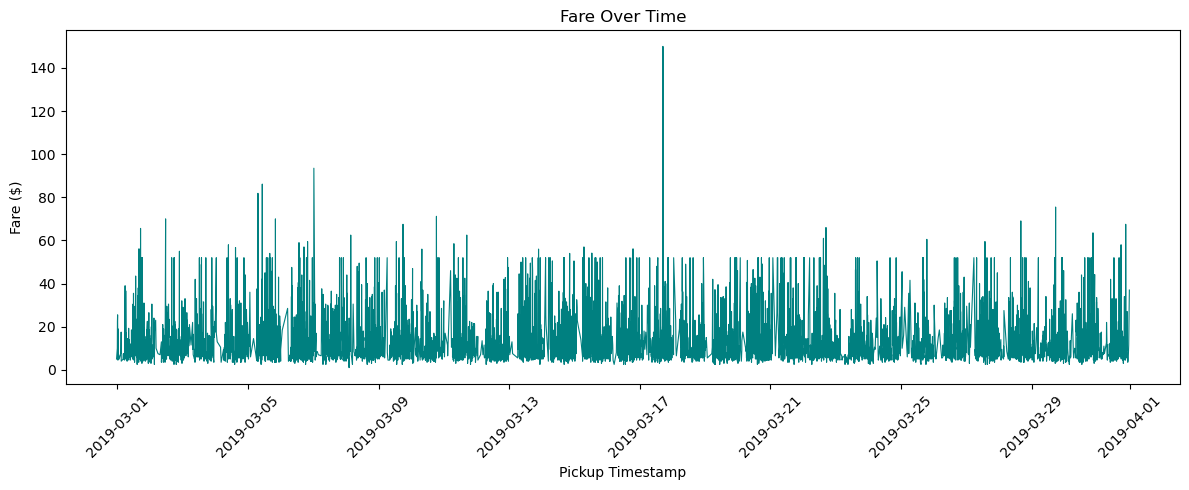

In [19]:
df["pickup"] = pd.to_datetime(df["pickup"])
df = df.sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(df["pickup"], df["fare"], color="teal", linewidth=0.8)
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# barchart total fare 

In [21]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()

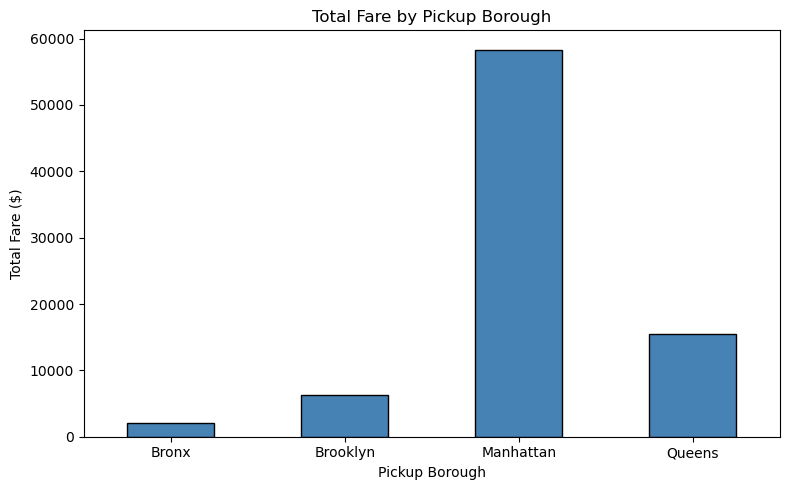

In [22]:
plt.figure(figsize=(8, 5))
borough_fare.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
# piechart trips by payment method

In [24]:
payment_counts = df["payment"].value_counts()

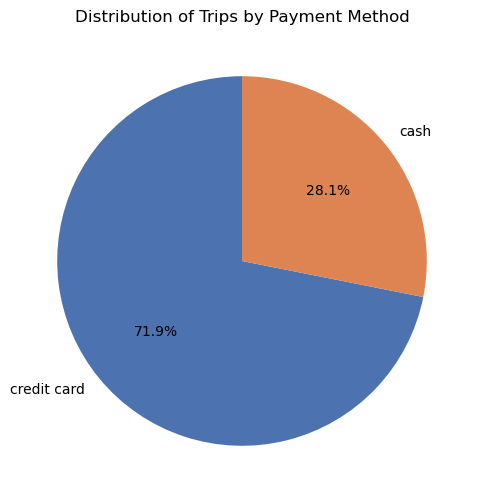

In [25]:
plt.figure(figsize=(6, 6))
plt.pie(payment_counts, labels=payment_counts.index, autopct="%1.1f%%",
        startangle=90, colors=["#4c72b0", "#dd8452"])
plt.title("Distribution of Trips by Payment Method")
plt.show()

In [26]:
# histogram distance

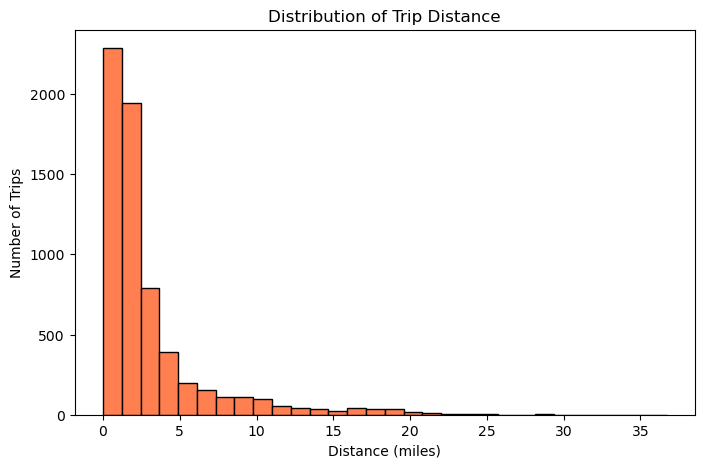

In [27]:
plt.figure(figsize=(8, 5))
plt.hist(df["distance"], bins=30, color="coral", edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")
plt.show()

In [28]:
#boxplot tip by pickup 

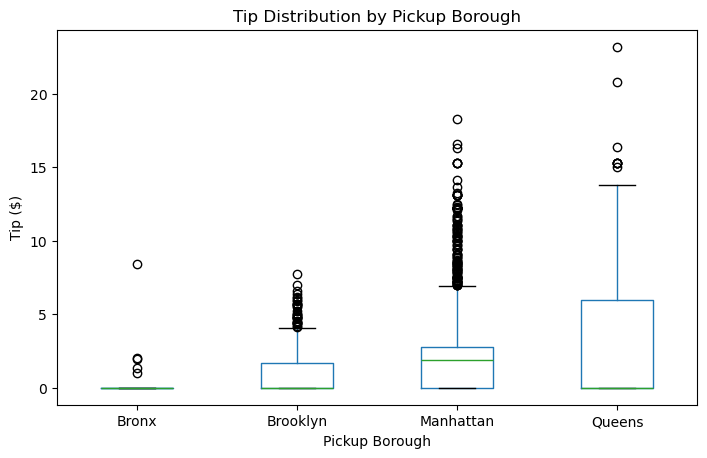

In [29]:
df.boxplot(column="tip", by="pickup_borough", figsize=(8, 5), grid=False)
plt.title("Tip Distribution by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.show()





In [30]:
# visualization using seaaborn count plot trips per borough

C:\Users\HASNA\AppData\Local\Temp\ipykernel_27704\2120566760.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="pickup_borough", palette="viridis")


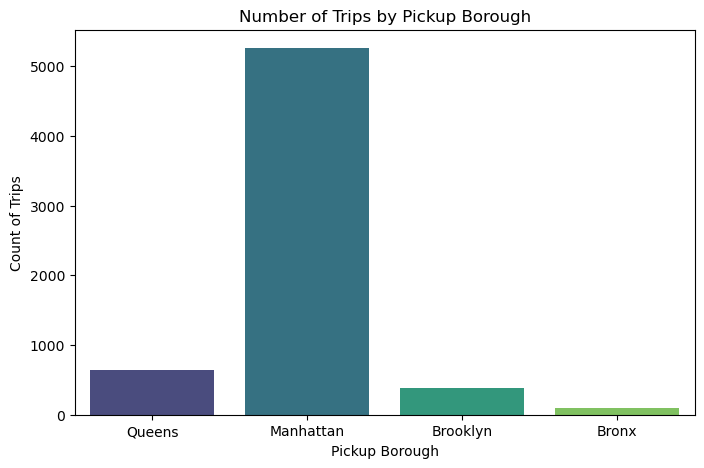

In [31]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="pickup_borough", palette="viridis")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Count of Trips")
plt.show()

In [32]:
#scatter plot distance vs fare

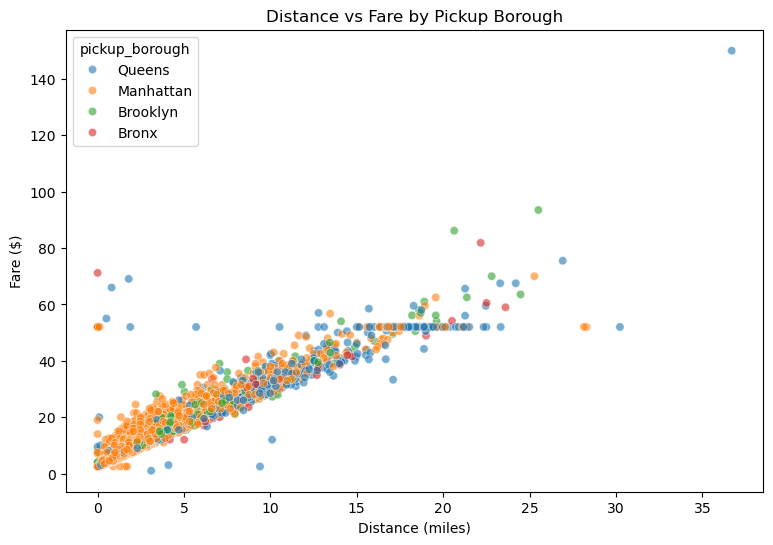

In [33]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough", alpha=0.6)
plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.show()

In [34]:
# heatmap correlation matrix 

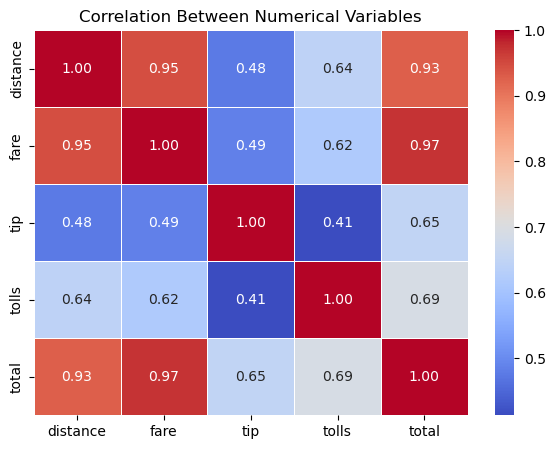

In [36]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Numerical Variables")
plt.show()

In [37]:
# pair plot corelated by pickup zone

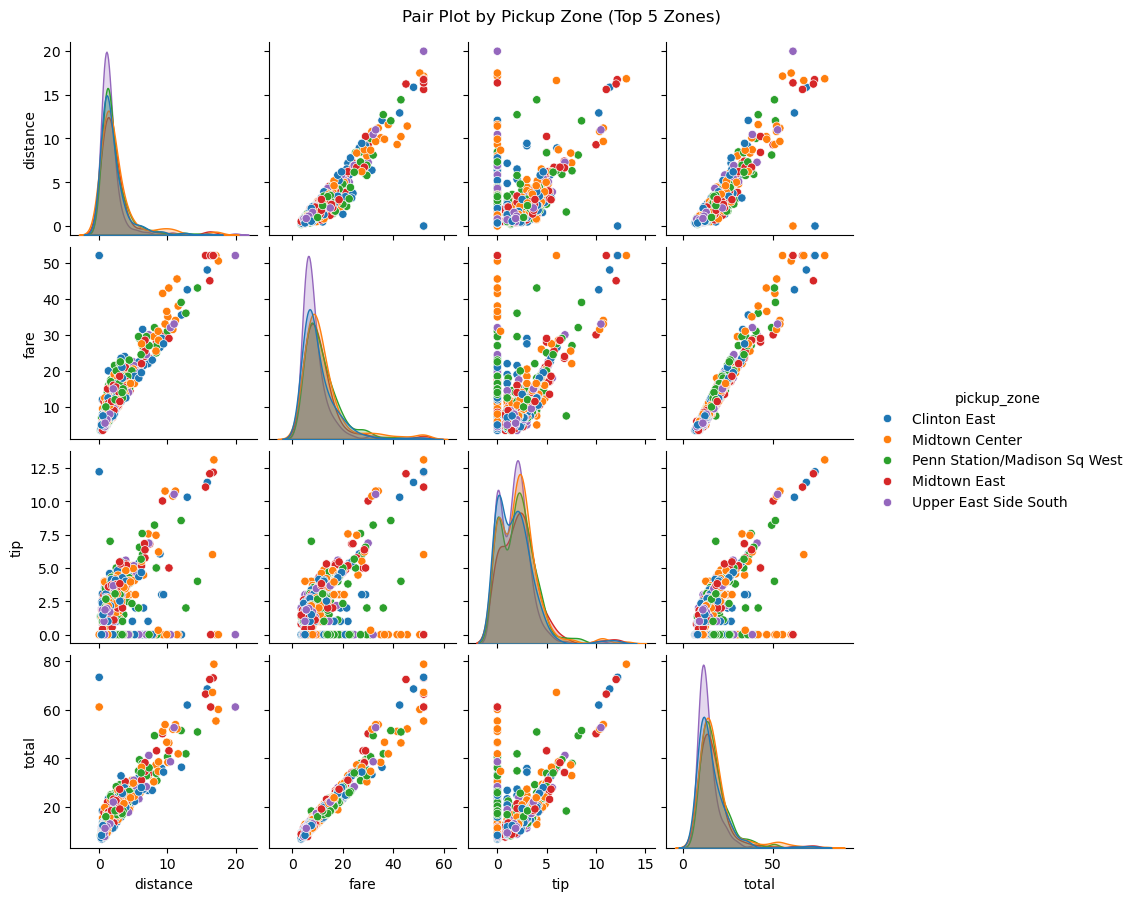

In [38]:
top_zones = df["pickup_zone"].value_counts().head(5).index
df_top = df[df["pickup_zone"].isin(top_zones)]

sns.pairplot(df_top, vars=["distance", "fare", "tip", "total"],
             hue="pickup_zone", diag_kind="kde", height=2.2)
plt.suptitle("Pair Plot by Pickup Zone (Top 5 Zones)", y=1.02)
plt.show()

In [39]:
#violin plot fare by payment method

C:\Users\HASNA\AppData\Local\Temp\ipykernel_27704\479656011.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="payment", y="fare", palette="Set2")


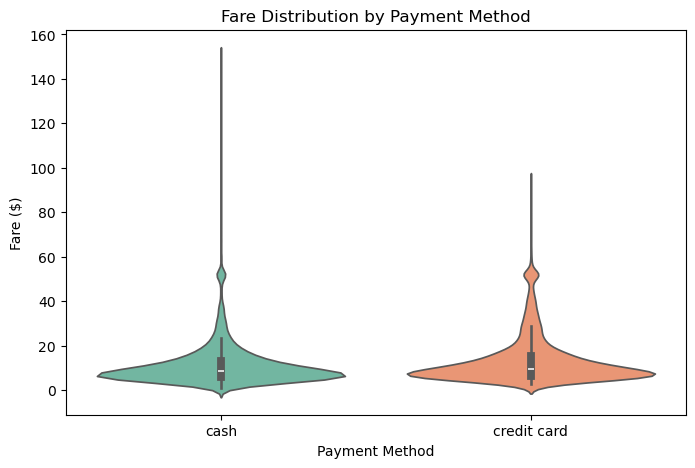

In [40]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="payment", y="fare", palette="Set2")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.show()